# Loss analysis: shear slab weight and D11

Use the same **14,776 ECTP slabs** as the manuscript to count successful pathways and explain losses. Shear slab weight has four pathways; D11 has 32. Every slab stays in the analysis, including slabs with no successful pathway.

1. Load and check the cohort
2. Shear weight: histogram, stepwise losses, and causes
3. D11: histogram, stepwise losses, and causes
4. Compare coverage and bottlenecks

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Works from paper_analysis/, examples/, the repository, or the Snow workspace.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "SnowPyt-MechParams"]
repo_root = next(p for p in candidates if (p / "src/snowpyt_mechparams").is_dir())
sys.path.insert(0, str(repo_root / "src"))
sys.path.insert(0, str(repo_root / "examples"))
sys.path.insert(0, str(repo_root / "paper_analysis"))

from notebook_utils import load_pits, create_ectp_slabs
from loss_analysis_utils import analyze_losses, plot_histogram, comparison_table

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 2)
warnings.filterwarnings("ignore", message="Using UFloat objects with std_dev==0.*", category=UserWarning)
plt.rcParams.update({"font.size": 10, "figure.dpi": 120})


def show_details(result, parameter, method=None, density_context=None):
    """Readable view; exact numeric bounds and counts remain in result.reasons."""
    frame = result.details(parameter, method, density_context)
    if frame.empty:
        print(f"{parameter}: no recorded failure causes.")
        return
    frame = frame.copy()
    frame["observed"] = [
        f"{low:g}–{high:g}" if pd.notna(low) else examples
        for low, high, examples in zip(
            frame.observed_min, frame.observed_max, frame.observed_examples
        )
    ]
    display(frame[["method", "density_context", "category", "reason", "field",
                   "grain_form", "resolved_grain_form", "slabs", "layers",
                   "observed", "interval", "unit"]])

## 1. Load and check the cohort

Parse the existing CAAML files in sorted filename order, then use `create_ectp_slabs`: one slab per ECTP result, containing the layers above its failure layer. Multiple tests in a pit remain separate slabs. Do not fill in missing slope or other observations.

In [2]:
pits = load_pits(str(repo_root / "examples/data"))
ectp_slabs = create_ectp_slabs(pits)
assert len(pits) == 50_278, "The input dataset differs from the manuscript."
assert len(ectp_slabs) == 14_776, "The ECTP cohort differs from the manuscript."
assert len({slab.slab_id for slab in ectp_slabs}) == len(ectp_slabs)
print(f"Loaded {len(pits):,} pits and {len(ectp_slabs):,} ECTP slabs.")

Loaded 50,278 pits and 14,776 ECTP slabs.


### How to read the loss tables

A pathway succeeds only when all its required layer calculations succeed and its target output is valid: finite shear weight (zero is allowed), or finite positive D11. Calculations propagate input measurement uncertainty only.

**Stepwise losses** use an explicit reporting order to assign each failed slab–pathway attempt to its first unsuccessful step. Each row reconciles `entering = surviving + newly_lost`. The newly lost slabs are partitioned into missing observations only, method validity limits only, both (mixed), or other errors. This order is a reporting convention for a branched dependency graph.

**Method causes** include all identifiable constraints, even on downstream branches. Missing upstream calculated density, E, or Poisson's ratio is labeled **blocked**, not a new missing observation. Density limits are checked only when the selected density method produces a finite value. An observed unsupported grain form is a validity failure; an absent grain form is missing data. Unknown hardness codes are recorded as other errors.

Cause counts overlap: a slab or layer can violate several constraints. `slabs` counts distinct ECTP slabs; `layers` counts distinct original layer observations, including a layer only once when it is shared by several slabs. Shared method steps are also counted once across pathways. `density_context` identifies the selected upstream density method for E and Srivastava; Köchle's Poisson's ratio is independent of density. Context counts must not be added to obtain a unique total.

The diagnostic tables follow the **implemented** domains. They impose no numerical density range on Schöttner and no grain-size range on Kim T6. Observed numeric ranges in the detail tables show the minimum and maximum violating values; validity intervals are in the displayed units. Empty intervals mean no numerical range applies. The complete detail table is available as `result.reasons`; use `show_details` to select a method or density context.

## 2. Shear slab weight

Reporting order: density → thickness / integrated weight → slope / shear weight.

In [3]:
weight = analyze_losses(ectp_slabs, "slab_weight_shear")
expected_weight_coverage = {
    "kim_jamieson_table2": 5_470, "geldsetzer": 4_187,
    "kim_jamieson_table6": 697, "data_flow": 109,
}
actual_weight_coverage = weight.coverage.set_index("density_method").successful_slabs.to_dict()
assert actual_weight_coverage == expected_weight_coverage
print(f"{len(weight.attempts):,} slab–pathway attempts; manuscript coverage reproduced.")
display(weight.coverage[["pathway", "successful_slabs", "coverage_percent"]])

slab_weight_shear:   0%|          | 0/14776 [00:00<?, ?slab/s]

59,104 slab–pathway attempts; manuscript coverage reproduced.


,pathway,successful_slabs,coverage_percent
0,Kim T2,5470,37.02
1,Geldsetzer,4187,28.34
2,Kim T6,697,4.72
3,Measured,109,0.74


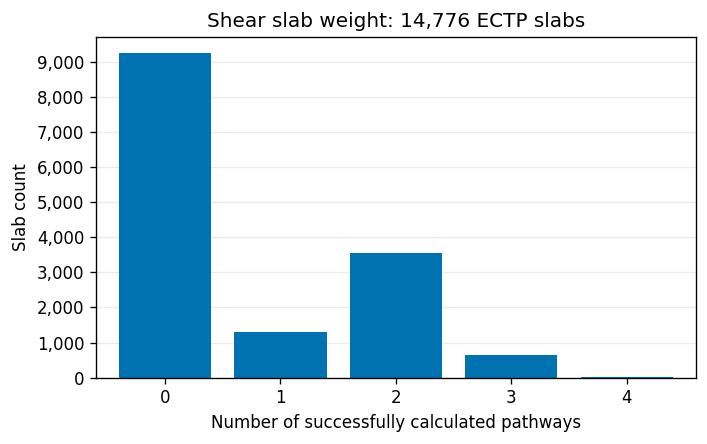

successful_pathways,0,1,2,3,4
slab_count,9241,1304,3554,657,20


In [4]:
plot_histogram(weight)
plt.show()
display(weight.histogram.to_frame().T)

### Stepwise slab losses

Each pathway starts with all 14,776 slabs. The final surviving count equals its successful calculated shear-weight count.

In [5]:
display(weight.stages)

,pathway,step,requirement,entering,surviving,newly_lost,missing_only,validity_only,mixed,other
0,Geldsetzer,1,Density,14776,4495,10281,3834,3158,2893,396
1,Geldsetzer,2,Thickness / integrated weight,4495,4495,0,0,0,0,0
2,Geldsetzer,3,Slope / shear weight,4495,4187,308,308,0,0,0
3,Kim T2,1,Density,14776,5907,8869,5165,1746,1562,396
4,Kim T2,2,Thickness / integrated weight,5907,5907,0,0,0,0,0
5,Kim T2,3,Slope / shear weight,5907,5470,437,437,0,0,0
6,Kim T6,1,Density,14776,736,14040,3811,2225,7608,396
7,Kim T6,2,Thickness / integrated weight,736,736,0,0,0,0,0
8,Kim T6,3,Slope / shear weight,736,697,39,39,0,0,0
9,Measured,1,Density,14776,109,14667,14667,0,0,0


### Method causes and details

The summary deduplicates affected slabs and layers within each method, upstream context, and cause category. The detail table separates unsupported grain codes, grain-specific hardness bounds, and missing density, hardness, grain form, or grain size. Slope loss is recorded at slab level, so its layer count is zero.

The density detail view initially shows Kim T2, the highest-coverage method. Change `DENSITY_METHOD` below to inspect Geldsetzer, Kim T6, or direct measurement; use `None` to show all density methods.

In [6]:
display(weight.method_summary)
DENSITY_METHOD = "kim_jamieson_table2"  # data_flow, geldsetzer, kim_jamieson_table6, or None
show_details(weight, "density", DENSITY_METHOD)
show_details(weight, "slab_weight")
show_details(weight, "slab_weight_shear")

,parameter,method,density_context,category,slabs,layers
0,density,data_flow,,missing,14667,49328
1,density,geldsetzer,,missing,6911,12428
2,density,geldsetzer,,other,396,427
3,density,geldsetzer,,validity,6415,8773
4,density,kim_jamieson_table2,,missing,6911,12428
5,density,kim_jamieson_table2,,other,396,427
6,density,kim_jamieson_table2,,validity,3606,4262
7,density,kim_jamieson_table6,,missing,11806,30559
8,density,kim_jamieson_table6,,other,396,427
9,density,kim_jamieson_table6,,validity,10183,18582


,method,density_context,category,reason,field,grain_form,resolved_grain_form,slabs,layers,observed,interval,unit
0,kim_jamieson_table2,,missing,absent observation,grain_form,,,3727,8792,,,
1,kim_jamieson_table2,,missing,absent observation,hand_hardness,,,938,1033,,,
2,kim_jamieson_table2,,missing,absent observation,hand_hardness,DF,DF,915,795,,,
3,kim_jamieson_table2,,missing,absent observation,hand_hardness,DFbk,DF,154,134,,,
4,kim_jamieson_table2,,missing,absent observation,hand_hardness,DFdc,DF,224,206,,,
5,kim_jamieson_table2,,missing,absent observation,hand_hardness,DHxr,DH,1,1,,,
6,kim_jamieson_table2,,missing,absent observation,hand_hardness,FC,FC,179,172,,,
7,kim_jamieson_table2,,missing,absent observation,hand_hardness,FCsf,FC,76,61,,,
8,kim_jamieson_table2,,missing,absent observation,hand_hardness,FCso,FC,94,88,,,
9,kim_jamieson_table2,,missing,absent observation,hand_hardness,FCxr,FCxr,232,214,,,


,method,density_context,category,reason,field,grain_form,resolved_grain_form,slabs,layers,observed,interval,unit
0,sum_layer_weight,,blocked,density step unsuccessful,density,,,14756,0,,,


,method,density_context,category,reason,field,grain_form,resolved_grain_form,slabs,layers,observed,interval,unit
0,slope_parallel_component,,blocked,integrated weight unsuccessful,slab_weight,,,14756,0,,,
1,slope_parallel_component,,missing,nonfinite observation,slope_angle,,,1061,0,,,degrees


## 3. D11

Reporting order: density → Young's modulus → Poisson's ratio → layer geometry → D11.

**Measured-density fallback has been removed from the dispatcher.** The explicitly selected direct-measurement pathway remains available. A failed empirical density step now blocks density-dependent calculations.

The previously saved D11 example counted 8,858 finite positive outputs, including 141 attempts on 20 slabs where the selected density method failed and measured density was used downstream. Those attempts no longer count as successful pathways. The corrected expected total is **8,717 successful attempts**. This notebook recomputes coverage on all slabs; it does not restrict the analysis to the manuscript's 317 slabs common to its top 16 pathways. The manuscript and saved example notebook have not been edited.

In [7]:
d11 = analyze_losses(ectp_slabs, "D11")
assert int(d11.attempts.success.sum()) == 8_717
assert 8_858 - int(d11.attempts.success.sum()) == 141
assert not d11.attempts.loc[~d11.attempts.density_ok, "success"].any()
print(f"{len(d11.attempts):,} attempts; {d11.attempts.success.sum():,} complete pathways succeeded.")
print(f"{d11.n_slabs - d11.histogram.loc[0]:,} slabs have at least one successful D11 pathway.")
display(d11.coverage[["pathway", "successful_slabs", "coverage_percent"]])

D11:   0%|          | 0/14776 [00:00<?, ?slab/s]

472,832 attempts; 8,717 complete pathways succeeded.
823 slabs have at least one successful D11 pathway.


,pathway,successful_slabs,coverage_percent
0,Kim T2 → Schöttner → Köchle,735,4.97
1,Kim T2 → Wautier → Köchle,735,4.97
2,Geldsetzer → Schöttner → Köchle,732,4.95
3,Geldsetzer → Wautier → Köchle,732,4.95
4,Geldsetzer → Köchle → Köchle,725,4.91
5,Kim T2 → Köchle → Köchle,626,4.24
6,Kim T2 → Bergfeld → Köchle,497,3.36
7,Geldsetzer → Bergfeld → Köchle,474,3.21
8,Geldsetzer → Schöttner → Srivastava,448,3.03
9,Geldsetzer → Wautier → Srivastava,448,3.03


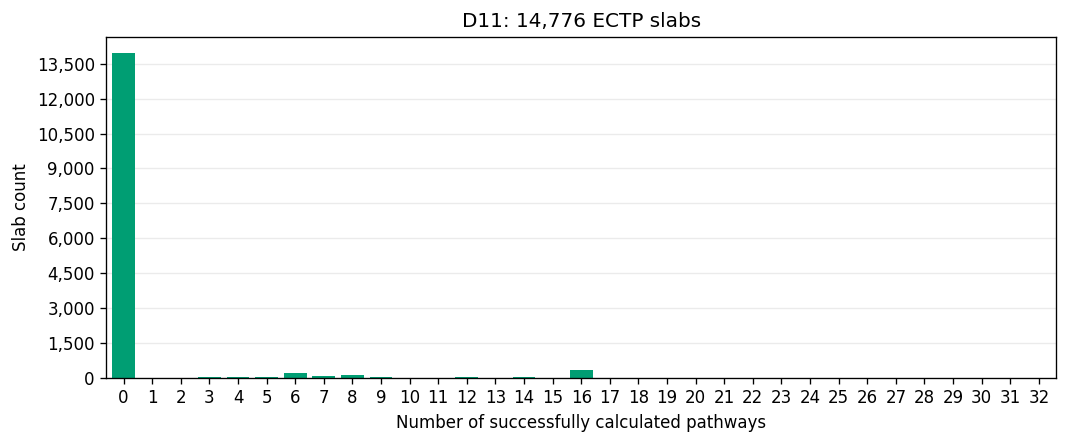

,slab_count
successful_pathways,
0,13953
1,5
2,7
3,17
4,10
5,36
6,200
7,63
8,94


In [8]:
plot_histogram(d11)
plt.show()
display(d11.histogram.to_frame())

### Stepwise slab losses

The table includes every step for all 32 pathways. Geometry includes observed thickness and depth. Other errors remain visible rather than being assigned to missing data or a published validity limit.

In [9]:
display(d11.stages)

,pathway,step,requirement,entering,surviving,newly_lost,missing_only,validity_only,mixed,other
0,Geldsetzer → Bergfeld → Köchle,1,Density,14776,4495,10281,3834,3158,2893,396
1,Geldsetzer → Bergfeld → Köchle,2,Young's modulus,4495,1207,3288,0,3288,0,0
2,Geldsetzer → Bergfeld → Köchle,3,Poisson's ratio,1207,474,733,0,733,0,0
3,Geldsetzer → Bergfeld → Köchle,4,Layer geometry,474,474,0,0,0,0,0
4,Geldsetzer → Bergfeld → Köchle,5,D11 calculation,474,474,0,0,0,0,0
5,Geldsetzer → Bergfeld → Srivastava,1,Density,14776,4495,10281,3834,3158,2893,396
6,Geldsetzer → Bergfeld → Srivastava,2,Young's modulus,4495,1207,3288,0,3288,0,0
7,Geldsetzer → Bergfeld → Srivastava,3,Poisson's ratio,1207,373,834,0,834,0,0
8,Geldsetzer → Bergfeld → Srivastava,4,Layer geometry,373,373,0,0,0,0,0
9,Geldsetzer → Bergfeld → Srivastava,5,D11 calculation,373,373,0,0,0,0,0


### Method causes

The summary includes every method and density context with a recorded cause. Unsupported downstream grain forms remain identifiable even if density could not be calculated; an unavailable density is listed separately as blocked.

In [10]:
display(d11.method_summary)

,parameter,method,density_context,category,slabs,layers
0,D11,weissgraeber_rosendahl,data_flow,blocked,14773,0
1,D11,weissgraeber_rosendahl,geldsetzer,blocked,14460,0
2,D11,weissgraeber_rosendahl,kim_jamieson_table2,blocked,14437,0
3,D11,weissgraeber_rosendahl,kim_jamieson_table6,blocked,14776,0
4,density,data_flow,,missing,14667,49328
5,density,geldsetzer,,missing,6911,12428
6,density,geldsetzer,,other,396,427
7,density,geldsetzer,,validity,6415,8773
8,density,kim_jamieson_table2,,missing,6911,12428
9,density,kim_jamieson_table2,,other,396,427


### Grain form, hardness, and density-range details

Density details are identical to the weight analysis because the same four density methods act on the same cohort. Below, choose any E method to inspect its grain-specific failures and the density values outside its validity range. The full table for all E methods is `d11.details("elastic_modulus")`. Poisson's-ratio details show all methods and density contexts.

In [11]:
E_METHOD = "bergfeld"  # bergfeld, kochle, wautier, or schottner
DENSITY_CONTEXT = None  # None for all; or data_flow, geldsetzer, kim_jamieson_table2/6
show_details(d11, "elastic_modulus", E_METHOD, DENSITY_CONTEXT)
show_details(d11, "poissons_ratio")
show_details(d11, "geometry")
show_details(d11, "D11")

,method,density_context,category,reason,field,grain_form,resolved_grain_form,slabs,layers,observed,interval,unit
0,bergfeld,data_flow,blocked,density step unsuccessful,density,,,3722,8782,,,
1,bergfeld,data_flow,blocked,density step unsuccessful,density,DF,DF,5640,6681,,,
2,bergfeld,data_flow,blocked,density step unsuccessful,density,DFbk,DF,1603,1578,,,
3,bergfeld,data_flow,blocked,density step unsuccessful,density,DFdc,DF,1621,1749,,,
4,bergfeld,data_flow,blocked,density step unsuccessful,density,DH,DH,92,92,,,
5,bergfeld,data_flow,blocked,density step unsuccessful,density,DHch,DH,10,10,,,
6,bergfeld,data_flow,blocked,density step unsuccessful,density,DHcp,DH,20,19,,,
7,bergfeld,data_flow,blocked,density step unsuccessful,density,DHla,DH,12,12,,,
8,bergfeld,data_flow,blocked,density step unsuccessful,density,DHpr,DH,7,7,,,
9,bergfeld,data_flow,blocked,density step unsuccessful,density,DHxr,DH,20,19,,,


,method,density_context,category,reason,field,grain_form,resolved_grain_form,slabs,layers,observed,interval,unit
0,kochle,,missing,absent observation,grain_form,,,3727,8792,,,
1,kochle,,validity,unsupported grain form,grain_form,DF,DF,5743,6824,DF,,
2,kochle,,validity,unsupported grain form,grain_form,DFbk,DF,1623,1601,DFbk,,
3,kochle,,validity,unsupported grain form,grain_form,DFdc,DF,1653,1788,DFdc,,
4,kochle,,validity,unsupported grain form,grain_form,IF,IF,474,517,IF,,
5,kochle,,validity,unsupported grain form,grain_form,IFic,IF,2,2,IFic,,
6,kochle,,validity,unsupported grain form,grain_form,IFil,IF,335,358,IFil,,
7,kochle,,validity,unsupported grain form,grain_form,IFrc,IF,884,886,IFrc,,
8,kochle,,validity,unsupported grain form,grain_form,IFsc,IF,264,273,IFsc,,
9,kochle,,validity,unsupported grain form,grain_form,MF,MF,419,504,MF,,


geometry: no recorded failure causes.


,method,density_context,category,reason,field,grain_form,resolved_grain_form,slabs,layers,observed,interval,unit
0,weissgraeber_rosendahl,data_flow,blocked,elastic_modulus step unsuccessful,elastic_modulus,,,14770,0,,,
1,weissgraeber_rosendahl,data_flow,blocked,poissons_ratio step unsuccessful,poissons_ratio,,,14771,0,,,
2,weissgraeber_rosendahl,geldsetzer,blocked,elastic_modulus step unsuccessful,elastic_modulus,,,14302,0,,,
3,weissgraeber_rosendahl,geldsetzer,blocked,poissons_ratio step unsuccessful,poissons_ratio,,,14392,0,,,
4,weissgraeber_rosendahl,kim_jamieson_table2,blocked,elastic_modulus step unsuccessful,elastic_modulus,,,14343,0,,,
5,weissgraeber_rosendahl,kim_jamieson_table2,blocked,poissons_ratio step unsuccessful,poissons_ratio,,,14396,0,,,
6,weissgraeber_rosendahl,kim_jamieson_table6,blocked,elastic_modulus step unsuccessful,elastic_modulus,,,14776,0,,,
7,weissgraeber_rosendahl,kim_jamieson_table6,blocked,poissons_ratio step unsuccessful,poissons_ratio,,,14770,0,,,


## 4. Compare coverage and bottlenecks

The first three count columns describe distinct slabs. Successful attempts and lost-attempt categories count slab–pathway pairs; D11 offers eight times as many pathways as shear weight. The loss-category columns assign each attempt to its first unsuccessful step and sum to total failed attempts.

The bottleneck table lists the three largest missing-observation and method-validity counts for each target. These are overlapping affected-slab counts within method contexts, not expected numbers of recoverable slabs. Blocked downstream steps are consequences of upstream loss and are excluded from this ranking.

In [12]:
display(comparison_table(weight, d11).T)

bottleneck_rows = []
for result in [weight, d11]:
    for category in ["missing", "validity"]:
        largest = (result.method_summary[result.method_summary.category == category]
                   .sort_values(["slabs", "parameter", "method", "density_context"],
                                ascending=[False, True, True, True]).head(3).copy())
        largest.insert(0, "target", result.target)
        bottleneck_rows.append(largest)
display(pd.concat(bottleneck_rows, ignore_index=True))

target,slab_weight_shear,D11
pathways,4,32
zero successful pathways,9241,13953
at least one successful pathway,5535,823
all pathways successful,20,0
successful slab–pathway attempts,10463,8717
lost attempts: missing_only,28261,219828
lost attempts: validity_only,7129,138275
lost attempts: mixed,12063,96508
lost attempts: other,1188,9504


,target,parameter,method,density_context,category,slabs,layers
0,slab_weight_shear,density,data_flow,,missing,14667,49328
1,slab_weight_shear,density,kim_jamieson_table6,,missing,11806,30559
2,slab_weight_shear,density,geldsetzer,,missing,6911,12428
3,slab_weight_shear,density,kim_jamieson_table6,,validity,10183,18582
4,slab_weight_shear,density,geldsetzer,,validity,6415,8773
5,slab_weight_shear,density,kim_jamieson_table2,,validity,3606,4262
6,D11,density,data_flow,,missing,14667,49328
7,D11,density,kim_jamieson_table6,,missing,11806,30559
8,D11,density,geldsetzer,,missing,6911,12428
9,D11,poissons_ratio,srivastava,kim_jamieson_table2,validity,12360,27446


### Reconciliation checks

Both histograms include every starting slab; all pathway-step partitions reconcile with the calculated successes. The detailed missing/validity/blocked counts intentionally overlap and are not summed.

In [13]:
for result in [weight, d11]:
    assert result.histogram.sum() == 14_776
    assert len(result.attempts) == 14_776 * result.n_pathways
    assert result.stages.newly_lost.sum() + result.attempts.success.sum() == len(result.attempts)
assert len(weight.histogram) == 5 and len(d11.histogram) == 33
print("Cohort, histogram, pathway coverage, and stepwise-loss checks passed.")

Cohort, histogram, pathway coverage, and stepwise-loss checks passed.
